# 07. Model comparison on the nine datasets

**Question.** How does the SP mixture compare with a Poisson process and with three
processes inferred by SVI (LGCP, Hawkes, Cox-Hawkes)?

**Data.** Cache of `scripts/compute_all.py` (`out/synthesis_cache/`, one file per
dataset), BSTPP models of notebook 09.
**Outputs.** `out/07_jsd_2pcf.csv`, `out/07_reproducibility.csv`, figures.
**Paper.** Table 2 and Fig. 1 (Sec. 4.2).
**Code.** `src/synthesis_utils.py`.

On each dataset, one extract of N = 3 000 nodes (or the full set if smaller), and each
model generates N nodes in the same border. The 2PCFs are compared with the
Jensen-Shannon divergence (JSD, lower is better), with the settings of Sec. 4.1 of the
paper. If the cache is empty, run `python scripts/compute_all.py` (incremental,
`--only "Belgium Cities"` for one dataset) after notebook 09.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve().parent.parent
sys.path.insert(0, str(ROOT / "src"))
import synthesis_utils as su

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11,
                     "axes.labelsize": 10, "font.size": 9})
MODELS = ["SP", "Poisson", "LGCP", "Hawkes", "Cox Hawkes"]
COLORS = {"data": "k", "SP": "#d62728", "Poisson": "#7f7f7f",
          "LGCP": "#1f77b4", "Hawkes": "#ff7f0e", "Cox Hawkes": "#2ca02c"}

LGCP, Hawkes and Cox-Hawkes are fitted by SVI with BSTPP (notebook 09). SP and Poisson
are generated directly. Only cache entries computed with the fitted models are kept
(key `Cox Hawkes_jsd`).

In [2]:
CACHE = {}
for name in su.available_cached():
    c = su.load_cached(name)
    if "Cox Hawkes_jsd" in c:
        CACHE[name] = c
cached = list(CACHE)
print("datasets in the cache:", cached)
if not cached:
    print("\n>>> empty cache, run:  python scripts/compute_all.py")

datasets in the cache: ['Austria Cities', 'Belgium Cities', 'RTE France', 'Gares France', 'ENEDIS France', 'France Communes', 'France Routes', 'Germany Stops', 'Swiss Stops']


## 1. Datasets

In [3]:
rows = []
for name, ds in su.DATASETS.items():
    rows.append(dict(dataset=name, N_total=ds["N"], gamma_data=ds["gamma_data"],
                     r0_km=round(ds["r0_data_m"] / 1e3, 1), eta=ds["eta"],
                     m_star=ds["m_star"], in_cache=name in CACHE))
pd.DataFrame(rows)

,dataset,N_total,gamma_data,r0_km,eta,m_star,in_cache
0,Austria Cities,2254,0.789,1.9,2,2142,True
1,Belgium Cities,815,0.808,3.1,2,718,True
2,RTE France,4932,0.931,12.4,6,3661,True
3,Gares France,3470,0.643,61.6,6,2896,True
4,ENEDIS France,912982,0.954,8.0,6,235268,True
5,France Communes,34269,0.254,0.3,2,24647,True
6,France Routes,897965,0.525,1.7,7,625121,True
7,Germany Stops,660298,0.612,4.4,4,413956,True
8,Swiss Stops,93288,0.873,6.7,12,56331,True


## 2. 2PCF of the data and of the models (one realisation)

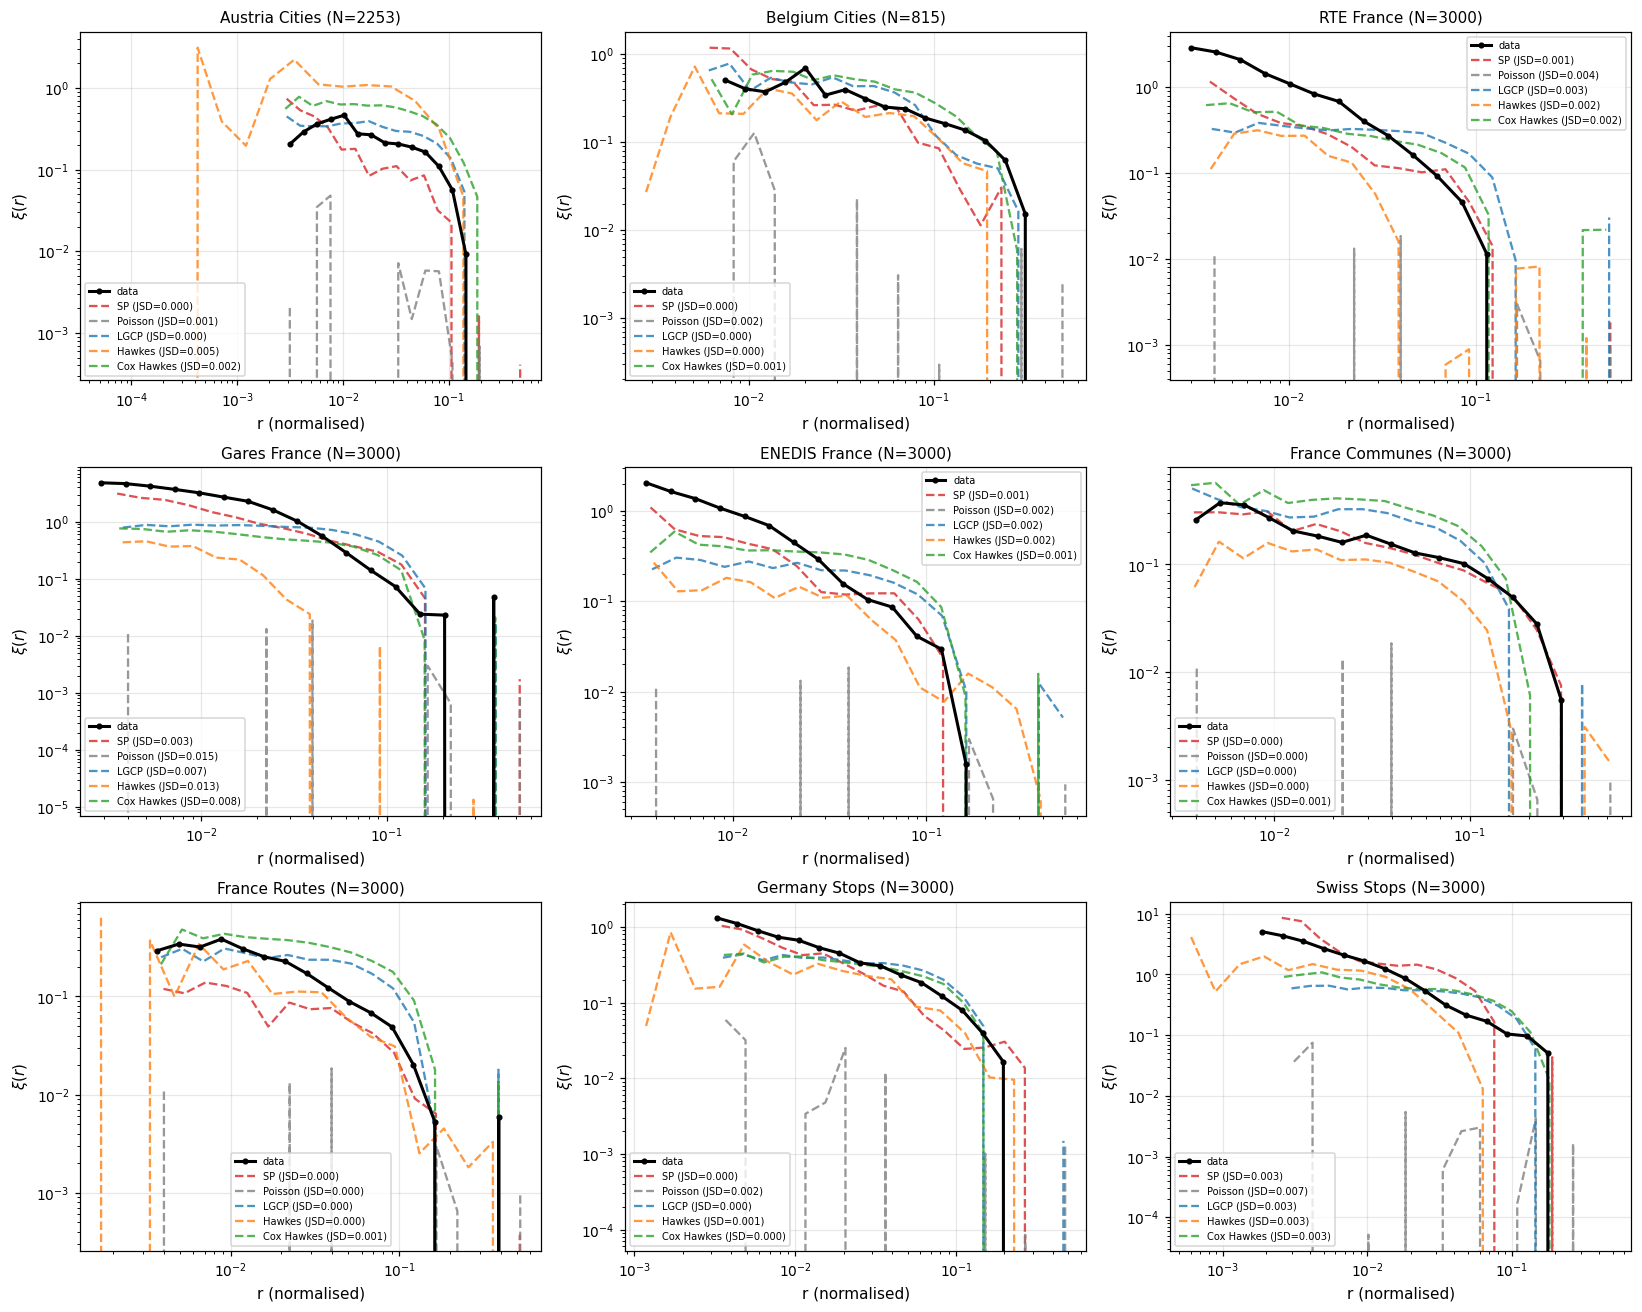

In [4]:
def plot_2pcf_grid(cache):
    n = len(cache); ncol = 3; nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, c) in zip(axes, cache.items()):
        ax.plot(c["data_r"], c["data_xi"], "-o", color="k", lw=2, ms=3,
                label="data", zorder=5)
        for m in MODELS:
            if f"{m}_r" not in c or c[f"{m}_r"] is None:
                continue
            ax.plot(c[f"{m}_r"], c[f"{m}_xi"], "--", color=COLORS[m], alpha=0.8,
                    label=f"{m} (JSD={float(c[f'{m}_jsd']):.3f})")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(f"{name} (N={int(c['N'])})", fontsize=10)
        ax.set_xlabel("r (normalised)"); ax.set_ylabel(r"$\xi(r)$")
        ax.legend(fontsize=6.5); ax.grid(alpha=0.3)
    for ax in axes[len(cache):]:
        ax.axis("off")
    fig.tight_layout(); plt.show()


plot_2pcf_grid(CACHE)

### JSD and ranks (Table 2)

The rank of each model is computed per dataset on the raw JSD, then averaged.

mean JSD rank (1 = best):
SP            1.78
Hawkes        2.67
LGCP          2.78
Cox Hawkes    3.22
Poisson       4.56


,SP,Poisson,LGCP,Hawkes,Cox Hawkes
dataset,,,,,
Austria Cities,0.0003,0.0009,0.0003,0.0047,0.0020
Belgium Cities,0.0005,0.0019,0.0003,0.0003,0.0006
RTE France,0.0013,0.0037,0.0028,0.0024,0.0019
Gares France,0.0030,0.0151,0.0073,0.0128,0.0080
ENEDIS France,0.0005,0.0024,0.0016,0.0015,0.0013
France Communes,0.0000,0.0005,0.0003,0.0001,0.0006
France Routes,0.0002,0.0004,0.0002,0.0001,0.0005
Germany Stops,0.0002,0.0018,0.0004,0.0007,0.0003
Swiss Stops,0.0033,0.0070,0.0030,0.0027,0.0030


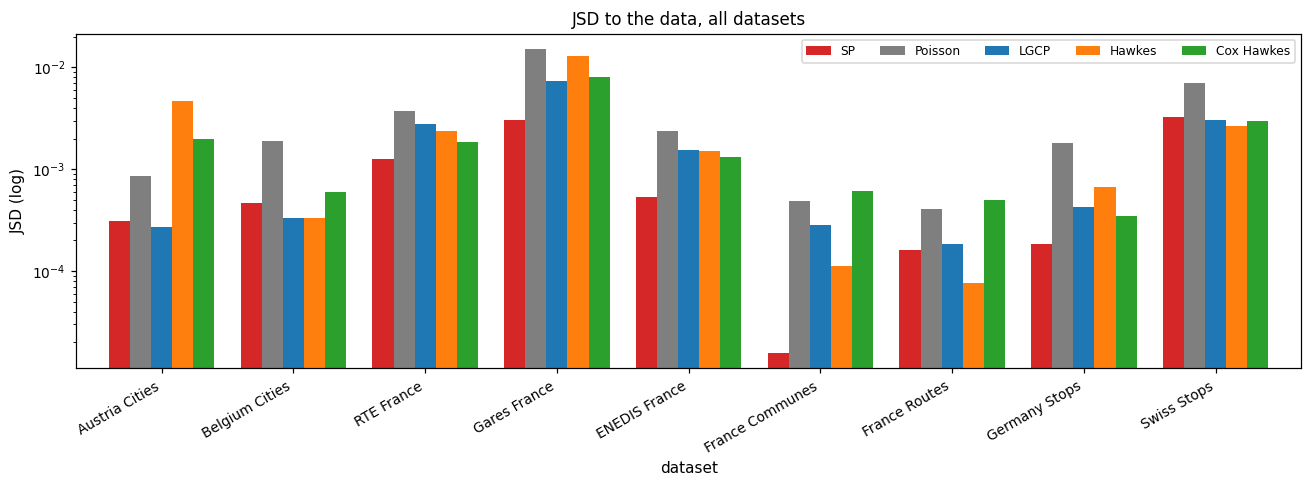

In [5]:
jsd_rows = []
for name, c in CACHE.items():
    row = {"dataset": name}
    for m in MODELS:
        row[m] = float(c[f"{m}_jsd"]) if f"{m}_jsd" in c else np.nan
    jsd_rows.append(row)
jsd_df = pd.DataFrame(jsd_rows).set_index("dataset")[MODELS]

ranks = jsd_df.rank(axis=1)                 # rank per dataset on the raw JSD, 1 = best
mean_rank = ranks.mean().sort_values()
print("mean JSD rank (1 = best):")
print(mean_rank.round(2).to_string())
display(jsd_df.round(4))
jsd_df.round(4).to_csv(ROOT / "out" / "07_jsd_2pcf.csv")

ax = jsd_df.plot(kind="bar", figsize=(12, 4.5), color=[COLORS[m] for m in MODELS],
                 logy=True, width=0.8)
ax.set_ylabel("JSD (log)"); ax.set_title("JSD to the data, all datasets")
ax.legend(fontsize=8, ncol=5); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.show()

## 3. Control: nearest-neighbour distances

The SP is calibrated on the 2PCF, the BSTPP models on the likelihood of the positions.
The JSD between the nearest-neighbour (NN) distance distributions is a summary that none
of them was calibrated on.

In [6]:
jsd_2pcf = pd.DataFrame({m: {n: float(c[f"{m}_jsd"]) for n, c in CACHE.items()}
                         for m in MODELS})
jsd_nn = pd.DataFrame({m: {n: float(c[f"nn_jsd_{m}"]) for n, c in CACHE.items()
                          if f"nn_jsd_{m}" in c} for m in MODELS})

print("=== mean rank (1 = best) ===")
comp = pd.DataFrame({
    "rank_2PCF (SP home ground)": jsd_2pcf.rank(axis=1).mean(),
    "rank_NN (neutral)": jsd_nn.rank(axis=1).mean(),
}).sort_values("rank_NN (neutral)")
display(comp.round(2))

print("\nNN JSD per dataset:")
display(jsd_nn.round(4))
jsd_nn.to_csv(ROOT / "out" / "07_jsd_nn.csv")

sp_nn_rank = jsd_nn.rank(axis=1)["SP"]
print(f"\nSP on the NN metric: best in {(sp_nn_rank == 1).sum()}/{len(sp_nn_rank)} datasets "
      f"(against {(jsd_2pcf.rank(axis=1)['SP'] == 1).sum()}/{len(jsd_2pcf)} on the 2PCF).")

=== mean rank (1 = best) ===


,rank_2PCF (SP home ground),rank_NN (neutral)
Cox Hawkes,3.22,2.11
SP,1.78,2.33
LGCP,2.78,2.67
Poisson,4.56,3.89
Hawkes,2.67,4.00



NN JSD per dataset:


,SP,Poisson,LGCP,Hawkes,Cox Hawkes
Austria Cities,0.0190,0.0038,0.0103,0.0726,0.0163
Belgium Cities,0.0503,0.0168,0.0381,0.0136,0.0262
RTE France,0.0587,0.1169,0.1057,0.1103,0.0883
Gares France,0.0347,0.0580,0.0244,0.0332,0.0190
ENEDIS France,0.0054,0.0266,0.0169,0.0186,0.0156
France Communes,0.0059,0.0077,0.0076,0.0076,0.0073
France Routes,0.0095,0.0129,0.0061,0.0428,0.0071
Germany Stops,0.0063,0.0294,0.0189,0.0613,0.0184
Swiss Stops,0.0468,0.1106,0.0836,0.1395,0.0651



SP on the NN metric: best in 5/9 datasets (against 5/9 on the 2PCF).


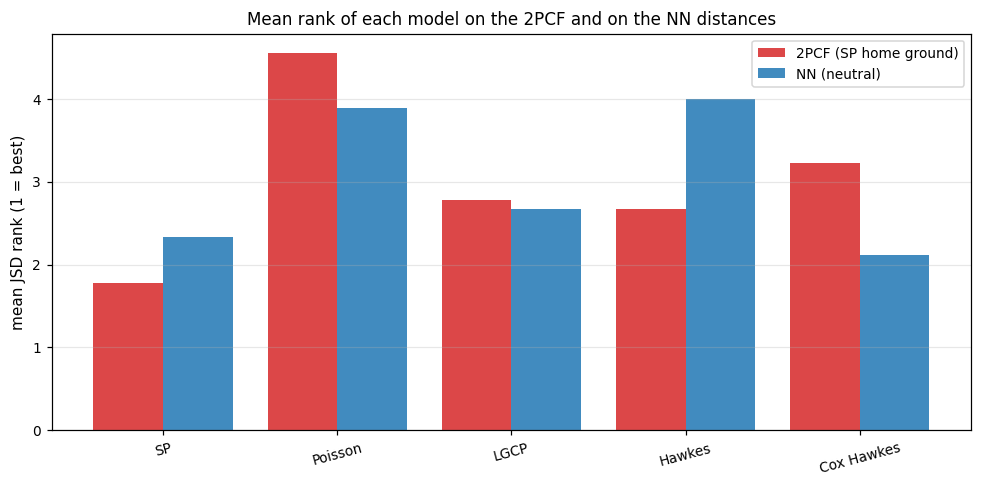

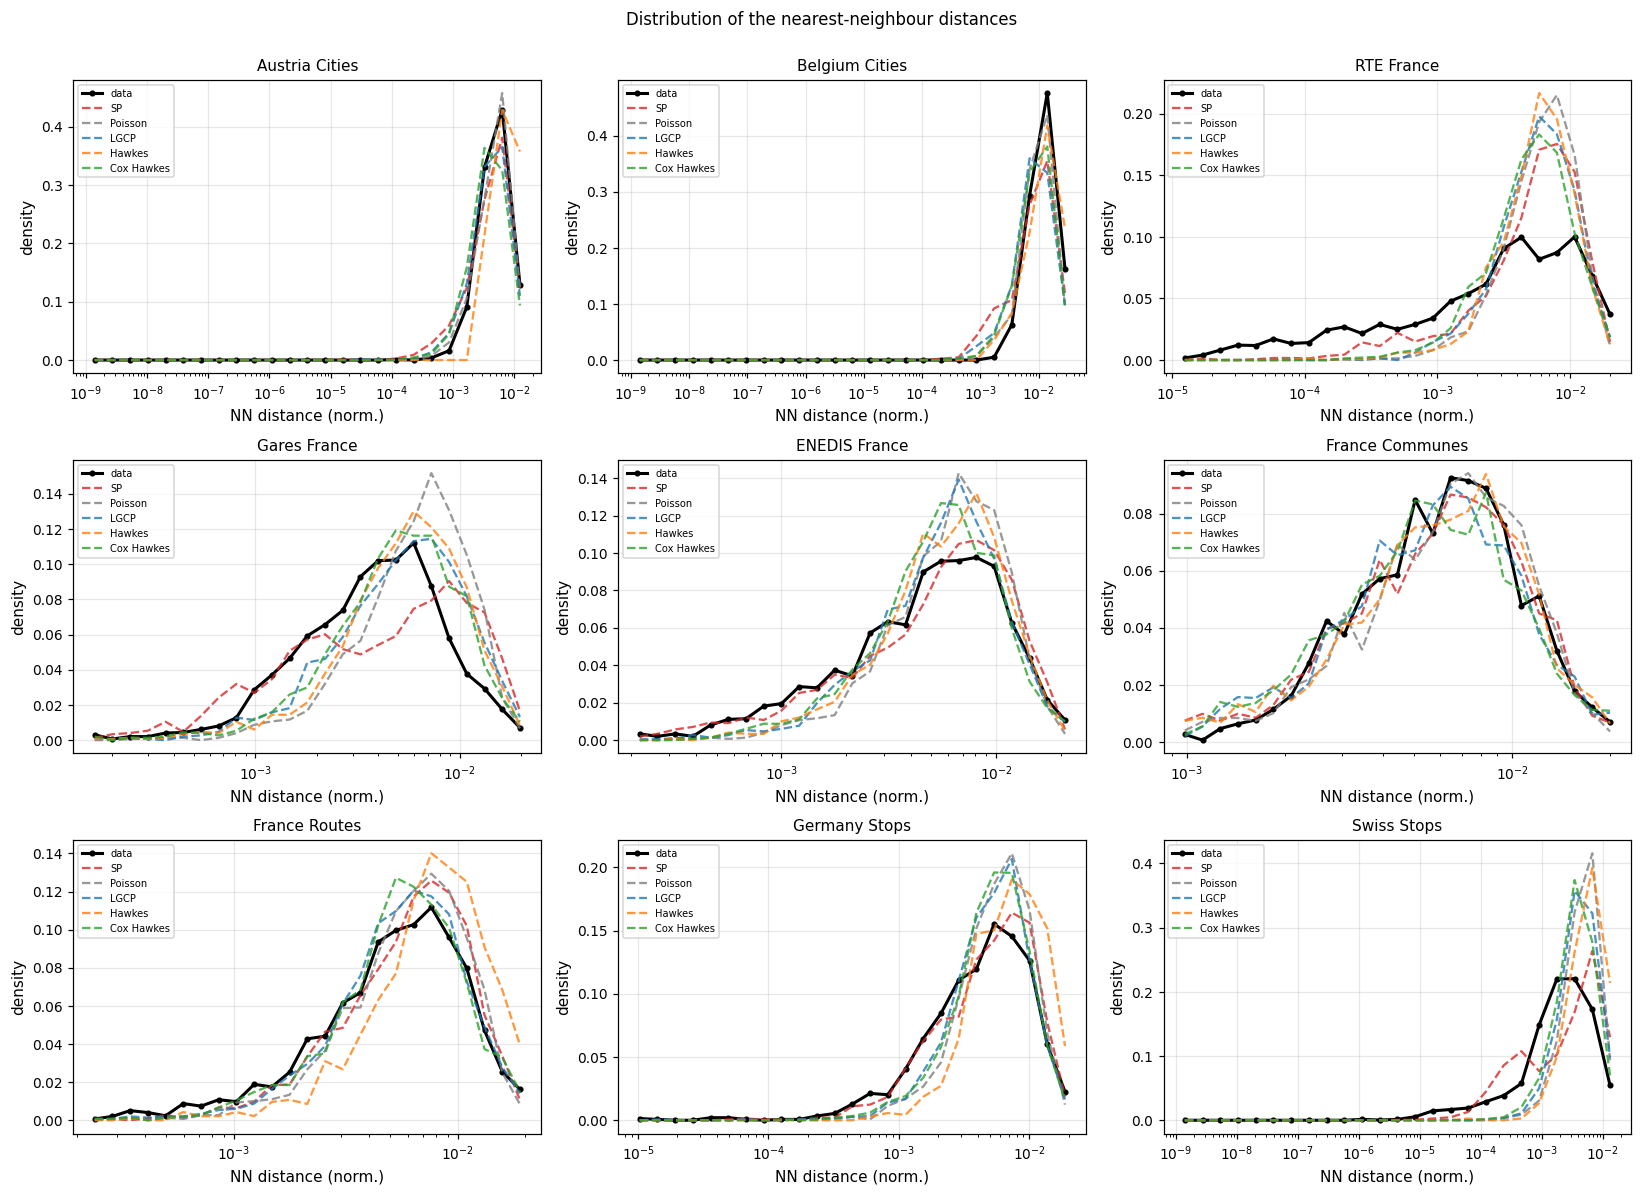

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(MODELS))
r2 = jsd_2pcf.rank(axis=1).mean()[MODELS]
rn = jsd_nn.rank(axis=1).mean()[MODELS]
ax.bar(x - 0.2, r2, 0.4, label="2PCF (SP home ground)", color="#d62728", alpha=0.85)
ax.bar(x + 0.2, rn, 0.4, label="NN (neutral)", color="#1f77b4", alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(MODELS, rotation=15)
ax.set_ylabel("mean JSD rank (1 = best)")
ax.set_title("Mean rank of each model on the 2PCF and on the NN distances")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

have = [(n, c) for n, c in CACHE.items() if "nn_r" in c]
ncol = 3; nrow = int(np.ceil(len(have) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 3.6 * nrow))
axes = np.atleast_1d(axes).ravel()
for ax, (name, c) in zip(axes, have):
    ax.plot(c["nn_r"], c["nn_data"], "-o", color="k", ms=3, lw=2, label="data")
    for m in MODELS:
        if f"nn_{m}" in c:
            ax.plot(c["nn_r"], c[f"nn_{m}"], "--", color=COLORS[m], alpha=0.8, label=m)
    ax.set_xscale("log"); ax.set_xlabel("NN distance (norm.)"); ax.set_ylabel("density")
    ax.set_title(name, fontsize=10); ax.legend(fontsize=6.5); ax.grid(alpha=0.3)
for ax in axes[len(have):]:
    ax.axis("off")
fig.suptitle("Distribution of the nearest-neighbour distances", y=1.0)
plt.tight_layout(); plt.show()

### NN fidelity of the SP against the size of the system

Hypothesis: on a small system the fractal has few levels and produces too many very
short distances. Left, NN JSD of the SP against N. Right, NN distributions on Belgium
(small) and Germany (large).

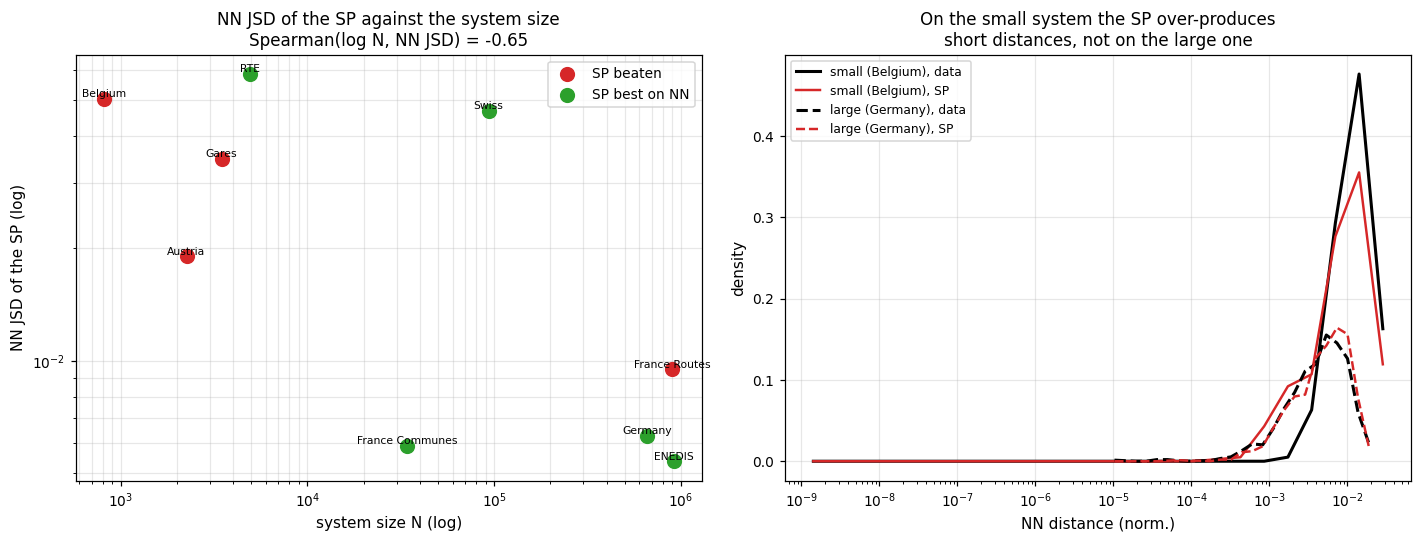

Spearman correlation (log N, NN JSD of the SP) = -0.65


In [8]:
from scipy.stats import spearmanr

rows = []
for name, c in CACHE.items():
    if "nn_r" not in c:
        continue
    N_sys = int(c["N_full"]) if "N_full" in c else int(c["N"])
    jsds = {m: float(c[f"nn_jsd_{m}"]) for m in MODELS if f"nn_jsd_{m}" in c}
    rows.append((name, N_sys, float(c["nn_jsd_SP"]), min(jsds, key=jsds.get) == "SP"))
diag = pd.DataFrame(rows, columns=["dataset", "N", "nn_jsd_SP", "sp_win"]
                    ).set_index("dataset")
rho_s = spearmanr(np.log(diag["N"]), diag["nn_jsd_SP"]).correlation

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for win, sub in diag.groupby("sp_win"):
    ax.scatter(sub["N"], sub["nn_jsd_SP"], s=80, zorder=3,
               c=("#2ca02c" if win else "#d62728"),
               label="SP best on NN" if win else "SP beaten")
for name, row in diag.iterrows():
    ax.annotate(name.replace(" Cities", "").replace(" France", "").replace(" Stops", ""),
                (row["N"], row["nn_jsd_SP"]), fontsize=7, ha="center", va="bottom")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("system size N (log)"); ax.set_ylabel("NN JSD of the SP (log)")
ax.set_title(f"NN JSD of the SP against the system size\n"
             f"Spearman(log N, NN JSD) = {rho_s:.2f}")
ax.legend(); ax.grid(alpha=0.3, which="both")

ax = axes[1]
for name, sty, lab in [("Belgium Cities", "-", "small (Belgium)"),
                       ("Germany Stops", "--", "large (Germany)")]:
    if name not in CACHE:
        continue
    c = CACHE[name]
    ax.plot(c["nn_r"], c["nn_data"], sty, color="k", lw=2, label=f"{lab}, data")
    ax.plot(c["nn_r"], c["nn_SP"], sty, color="#d62728", lw=1.6, label=f"{lab}, SP")
ax.set_xscale("log"); ax.set_xlabel("NN distance (norm.)"); ax.set_ylabel("density")
ax.set_title("On the small system the SP over-produces\nshort distances, not on the large one")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"Spearman correlation (log N, NN JSD of the SP) = {rho_s:.2f}")

## 4. Cost

Exponent α of t ∝ N^α for the total time, from `out/benchmark_complexity.csv`
(notebook 08).

exponent alpha (total time, t ~ N^alpha):
Model
SP            0.155
LGCP         -0.336
Hawkes        0.588
Cox Hawkes    0.678


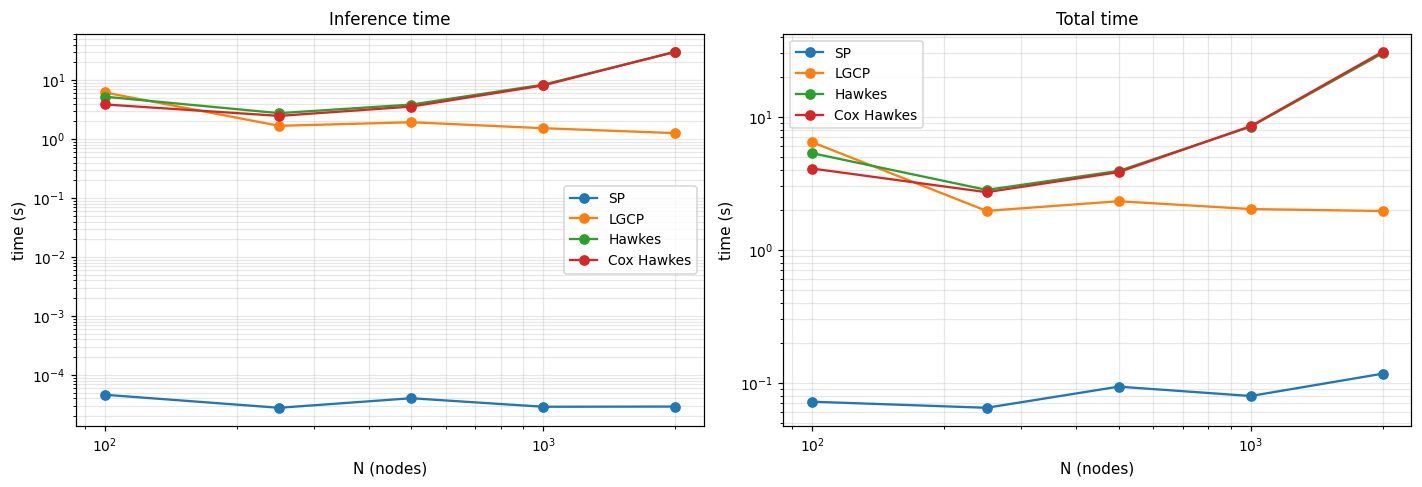

In [9]:
cx = pd.read_csv(ROOT / "out" / "benchmark_complexity.csv")
alpha_tot = cx[cx.Phase == "total"][["Model", "alpha"]].set_index("Model")["alpha"]
print("exponent alpha (total time, t ~ N^alpha):")
print(alpha_tot.round(3).to_string())

bench = pd.read_csv(ROOT / "out" / "benchmark_results.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m in bench.Model.unique():
    sub = bench[bench.Model == m].sort_values("N")
    axes[0].plot(sub.N, sub.t_inference_mean, "o-", label=m)
    axes[1].plot(sub.N, sub.t_total_mean, "o-", label=m)
for ax, t in zip(axes, ["Inference time", "Total time"]):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("N (nodes)"); ax.set_ylabel("time (s)")
    ax.set_title(t); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

## 5. Ranking against N

Same comparison for N = 200, 500, 1 000, 2 000, 4 000 (capped at the dataset size). The
three largest datasets (ENEDIS, French roads, German stops) are left out, since loading
them takes about 30 min.

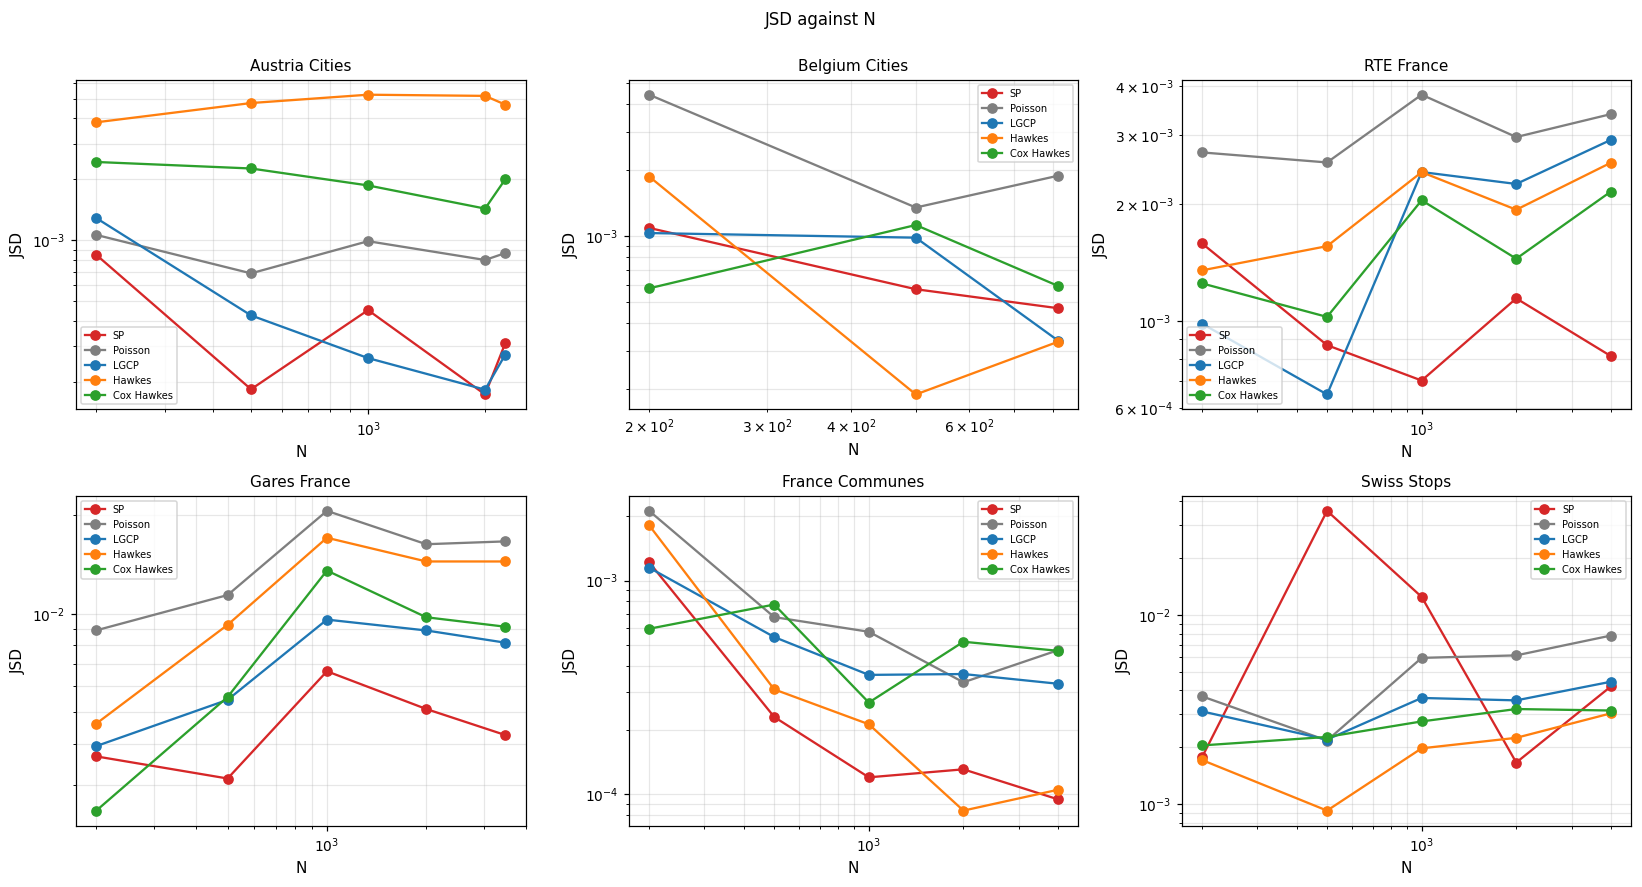

SP is the best model in 14/28 points (dataset × N) of the sweep.


In [10]:
def plot_sweep_grid(cache):
    have = [(n, c) for n, c in cache.items() if "sweep_N" in c]
    if not have:
        print("no sweep in the cache (run scripts/compute_all.py)."); return
    ncol = 3; nrow = int(np.ceil(len(have) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, c) in zip(axes, have):
        Ns = c["sweep_N"]
        for m in MODELS:
            if f"sweep_jsd_{m}" not in c:
                continue
            ax.plot(Ns, c[f"sweep_jsd_{m}"], "o-", color=COLORS[m], label=m)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("N"); ax.set_ylabel("JSD")
        ax.set_title(name, fontsize=10); ax.grid(alpha=0.3, which="both")
        ax.legend(fontsize=6.5)
    for ax in axes[len(have):]:
        ax.axis("off")
    fig.suptitle("JSD against N", y=1.0)
    fig.tight_layout(); plt.show()


plot_sweep_grid(CACHE)

wins = tot = 0
for name, c in CACHE.items():
    if "sweep_N" not in c:
        continue
    for i in range(len(c["sweep_N"])):
        jsds = {m: c[f"sweep_jsd_{m}"][i] for m in MODELS
                if f"sweep_jsd_{m}" in c and np.isfinite(c[f"sweep_jsd_{m}"][i])}
        if jsds and min(jsds, key=jsds.get) == "SP":
            wins += 1
        tot += 1
if tot:
    print(f"SP is the best model in {wins}/{tot} points (dataset × N) of the sweep.")

## 6. Ten realisations per model

Mean 2PCF ± σ over 10 independent realisations, and mean JSD ± σ.

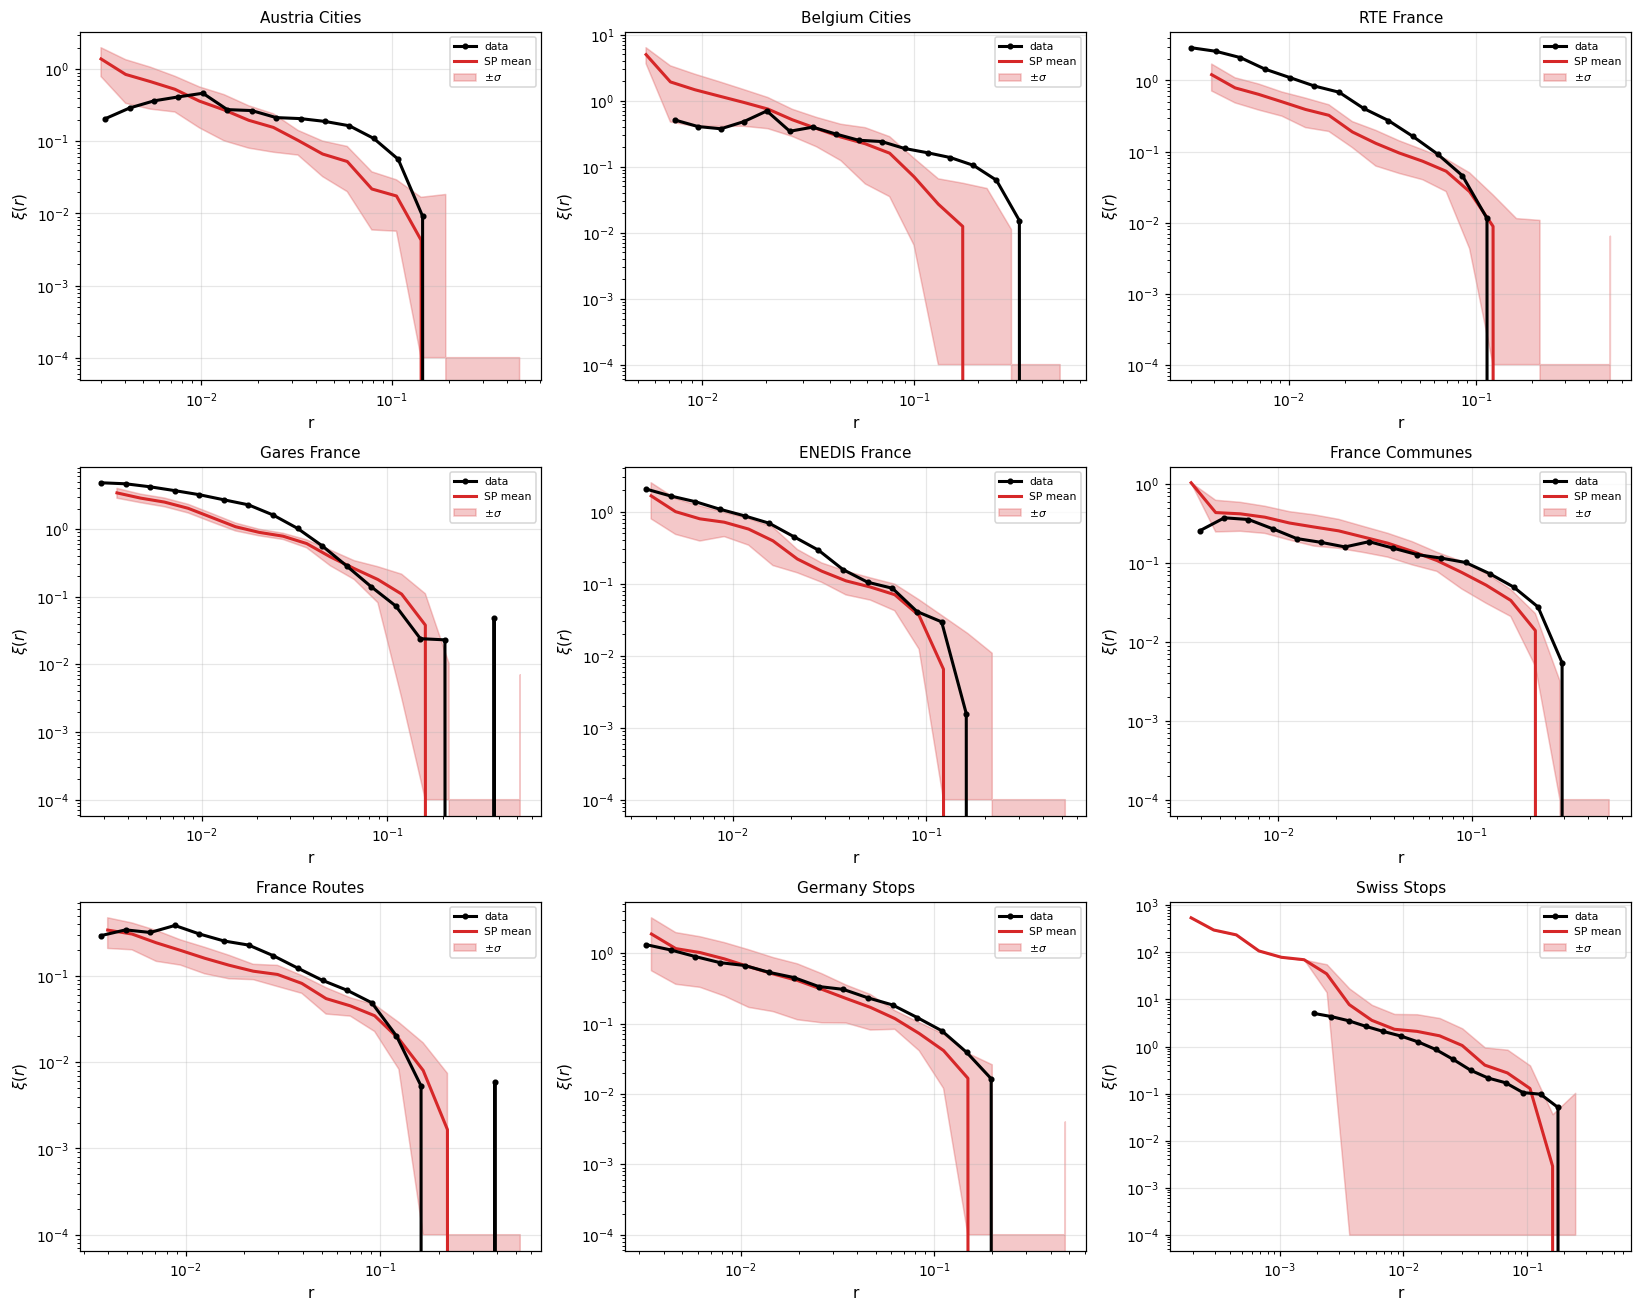

In [11]:
def plot_sp_band_grid(cache):
    have = [(n, c) for n, c in cache.items() if c.get("stoch_r") is not None]
    ncol = 3; nrow = int(np.ceil(len(have) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, c) in zip(axes, have):
        r, mu, sd = c["stoch_r"], c["stoch_xi_mean"], c["stoch_xi_std"]
        ax.plot(c["data_r"], c["data_xi"], "-o", color="k", lw=2, ms=3,
                label="data", zorder=5)
        ax.plot(r, mu, "-", color=COLORS["SP"], lw=2, label="SP mean")
        ax.fill_between(r, np.clip(mu - sd, 1e-4, None), mu + sd,
                        color=COLORS["SP"], alpha=0.25, label=r"$\pm\sigma$")
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_title(name, fontsize=10)
        ax.set_xlabel("r"); ax.set_ylabel(r"$\xi(r)$")
        ax.legend(fontsize=7); ax.grid(alpha=0.3)
    for ax in axes[len(have):]:
        ax.axis("off")
    fig.tight_layout(); plt.show()


plot_sp_band_grid(CACHE)

average over the datasets, accuracy and reproducibility:


,mean JSD (accuracy),sigma_JSD (reproducibility)
SP,0.0019,0.0029
Poisson,0.0038,0.0002
LGCP,0.0026,0.0002
Hawkes,0.0133,0.0087
Cox Hawkes,0.0016,0.0006


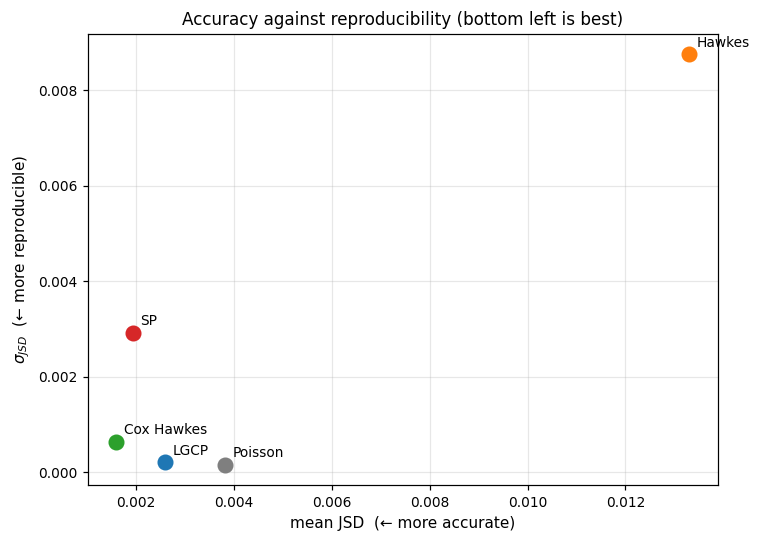

In [12]:
jm = pd.DataFrame({m: {n: float(c[f"band_{m}_jsd_mean"]) for n, c in CACHE.items()
                       if f"band_{m}_jsd_mean" in c} for m in MODELS})
js = pd.DataFrame({m: {n: float(c[f"band_{m}_jsd_std"]) for n, c in CACHE.items()
                       if f"band_{m}_jsd_std" in c} for m in MODELS})

repro = pd.DataFrame({
    "mean JSD (accuracy)": jm.mean(),
    "sigma_JSD (reproducibility)": js.mean(),
}).loc[MODELS]
print("average over the datasets, accuracy and reproducibility:")
display(repro.round(4))
repro.to_csv(ROOT / "out" / "07_reproducibility.csv")

fig, ax = plt.subplots(figsize=(7, 5))
for m in MODELS:
    ax.scatter(jm[m].mean(), js[m].mean(), s=90, color=COLORS[m], zorder=3)
    ax.annotate(m, (jm[m].mean(), js[m].mean()), fontsize=9,
                xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("mean JSD  (← more accurate)")
ax.set_ylabel(r"$\sigma_{JSD}$  (← more reproducible)")
ax.set_title("Accuracy against reproducibility (bottom left is best)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Population marks (not in the paper)

Population is given to the nodes of the full SP tree as ∝ η^(−slope × level), with the
slope fitted on the rank-size (Zipf) exponent of the data. The baseline is a marked
Hawkes process, where the population of a node modulates its self-excitation. Coupling
between population and position: Δγ = γ_hi − γ_lo (top 20 % against the rest) and the
mark correlation k_mm(r).

rank-size (Zipf) exponent, the SP slope is fitted on the data:


,zipf_data,zipf_SP,slope_SP
dataset,,,
Austria Cities,1.02,1.03,1.07
Belgium Cities,1.23,1.16,1.23
RTE France,1.66,1.54,2.00
Gares France,1.37,1.31,1.69
ENEDIS France,1.91,1.54,2.00
France Communes,1.30,1.33,1.38
France Routes,1.71,1.43,2.00
Germany Stops,1.26,1.31,1.54
Swiss Stops,1.48,1.20,2.00


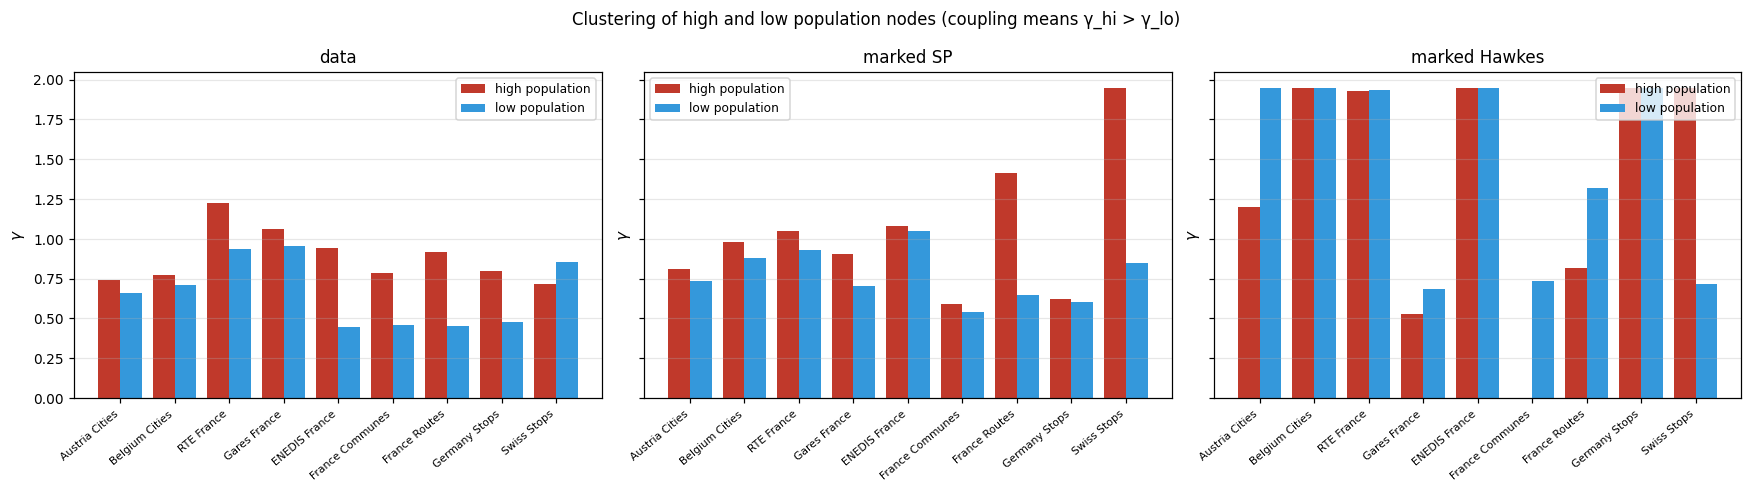


Δγ = γ_hi − γ_lo (population-structure coupling, > 0 expected):


,data,marked SP,marked Hawkes
dataset,,,
Austria Cities,0.08,0.08,-0.75
Belgium Cities,0.06,0.10,-0.00
RTE France,0.29,0.12,-0.00
Gares France,0.10,0.20,-0.15
ENEDIS France,0.50,0.03,-0.00
France Communes,0.33,0.05,NaN
France Routes,0.46,0.77,-0.51
Germany Stops,0.32,0.02,0.00
Swiss Stops,-0.14,1.10,1.24


correlation of the coupling, model against data (Δγ):
  marked SP     : -0.38
  marked Hawkes : -0.50


In [13]:
zipf = pd.DataFrame([
    dict(dataset=n, zipf_data=round(float(c["zipf_data"]), 2),
         zipf_SP=round(float(c["zipf_sp"]), 2), slope_SP=round(float(c["sp_slope"]), 2))
    for n, c in CACHE.items() if "zipf_data" in c]).set_index("dataset")
print("rank-size (Zipf) exponent, the SP slope is fitted on the data:")
display(zipf)

mk_rows = []
for name, c in CACHE.items():
    if "mh_gamma_hi" not in c:
        continue
    row = {"dataset": name}
    for tag in ("data", "sp", "mh"):
        row[f"{tag}_hi"] = float(c[f"{tag}_gamma_hi"])
        row[f"{tag}_lo"] = float(c[f"{tag}_gamma_lo"])
    mk_rows.append(row)
mk = pd.DataFrame(mk_rows).set_index("dataset")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, (lab, tag) in zip(axes, [("data", "data"), ("marked SP", "sp"),
                                 ("marked Hawkes", "mh")]):
    x = np.arange(len(mk))
    ax.bar(x - 0.2, mk[f"{tag}_hi"], 0.4, label="high population", color="#c0392b")
    ax.bar(x + 0.2, mk[f"{tag}_lo"], 0.4, label="low population", color="#3498db")
    ax.set_xticks(x); ax.set_xticklabels(mk.index, rotation=40, ha="right", fontsize=7)
    ax.set_title(lab); ax.set_ylabel(r"$\gamma$"); ax.legend(fontsize=8)
    ax.grid(alpha=0.3, axis="y")
fig.suptitle("Clustering of high and low population nodes (coupling means γ_hi > γ_lo)")
plt.tight_layout(); plt.show()

dgamma = pd.DataFrame({
    "data": mk["data_hi"] - mk["data_lo"],
    "marked SP": mk["sp_hi"] - mk["sp_lo"],
    "marked Hawkes": mk["mh_hi"] - mk["mh_lo"],
})
print("\nΔγ = γ_hi − γ_lo (population-structure coupling, > 0 expected):")
display(dgamma.round(2))
print("correlation of the coupling, model against data (Δγ):")
print(f"  marked SP     : {dgamma['data'].corr(dgamma['marked SP']):.2f}")
print(f"  marked Hawkes : {dgamma['data'].corr(dgamma['marked Hawkes']):.2f}")

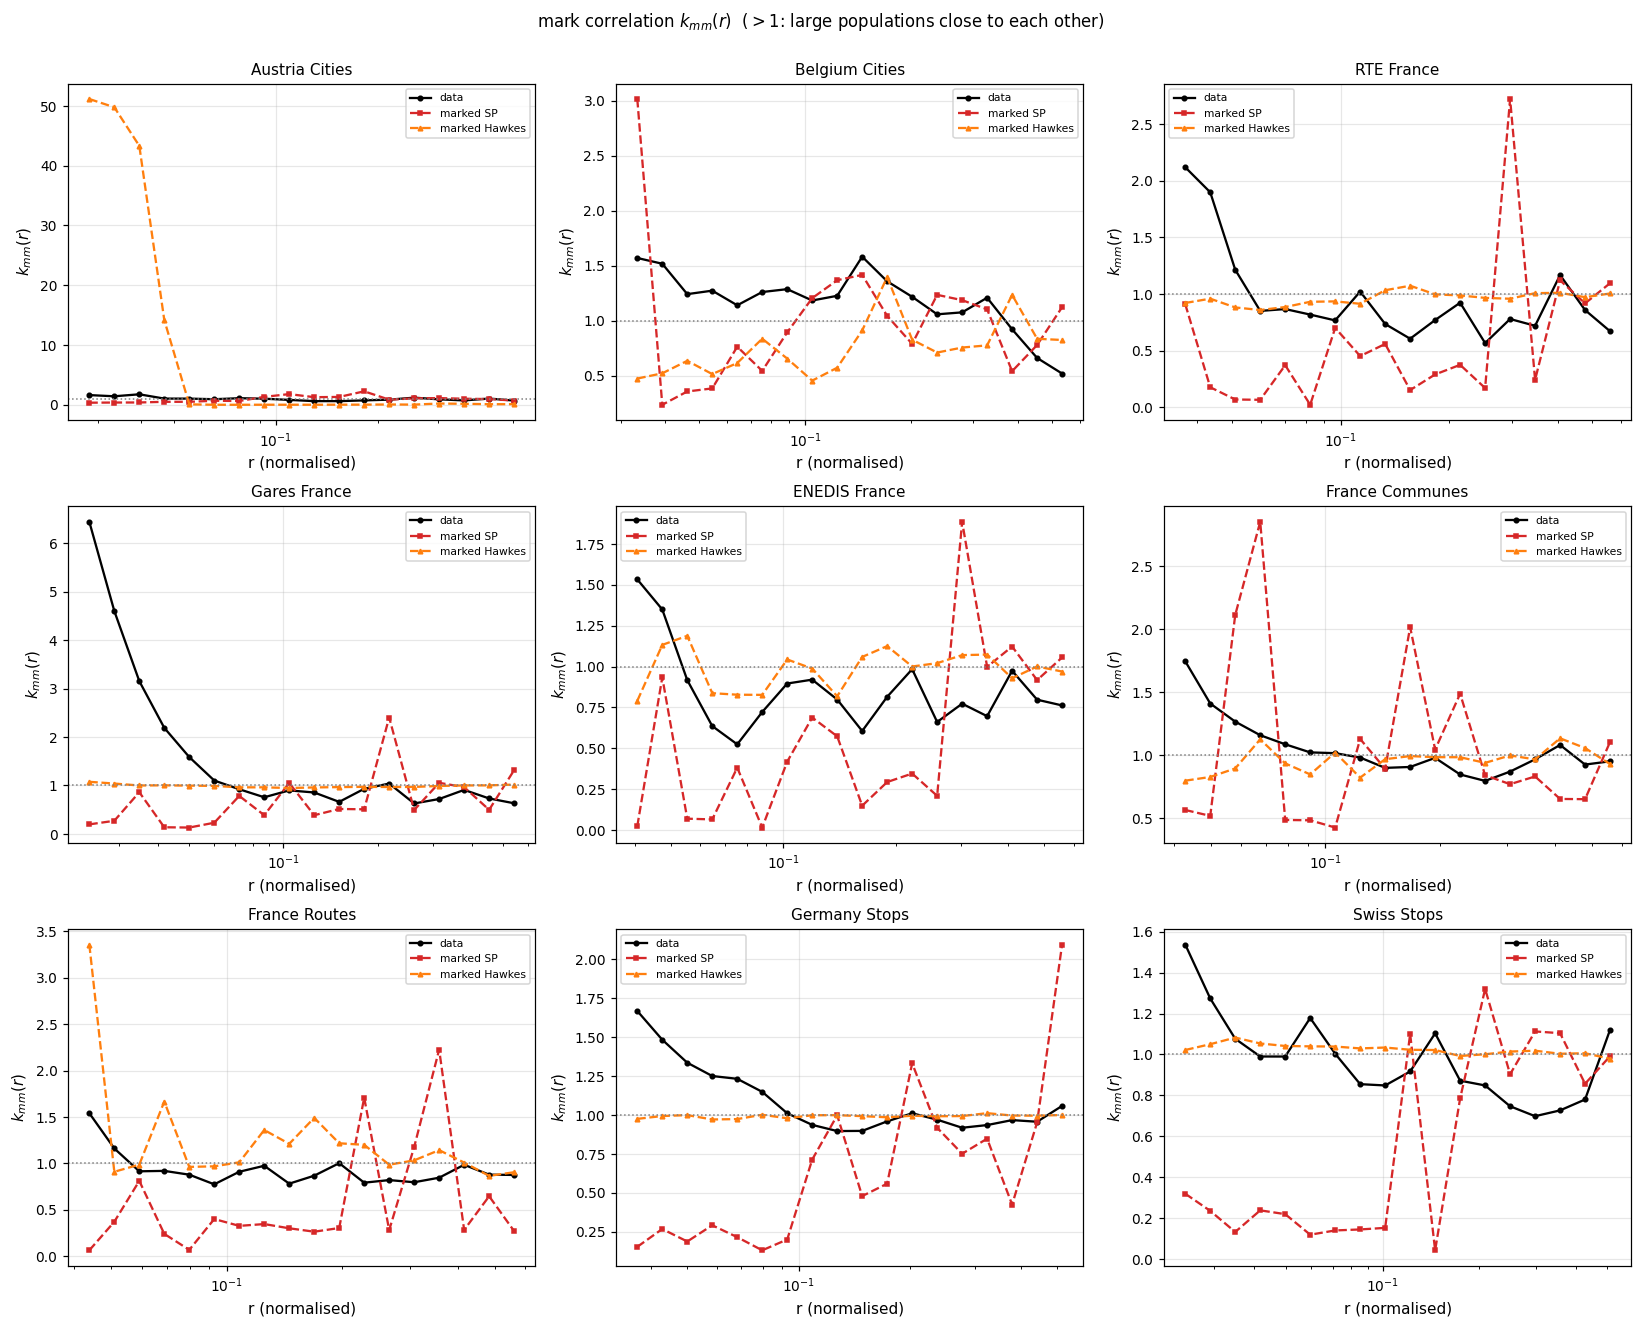

In [14]:
def plot_markcorr_grid(cache):
    have = [(n, c) for n, c in cache.items() if "markcorr_r" in c]
    if not have:
        print("no mark correlation in the cache for these datasets."); return
    ncol = 3; nrow = int(np.ceil(len(have) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5 * ncol, 4 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, (name, c) in zip(axes, have):
        r = c["markcorr_r"]
        ax.plot(r, c["data_kmm"], "-o", color="k", ms=3, label="data")
        ax.plot(r, c["sp_kmm"], "--s", color=COLORS["SP"], ms=3, label="marked SP")
        if "mh_kmm" in c:
            ax.plot(r, c["mh_kmm"], "--^", color=COLORS["Hawkes"], ms=3,
                    label="marked Hawkes")
        ax.axhline(1.0, color="gray", ls=":", lw=1)     # k_mm = 1, no coupling
        ax.set_xscale("log")
        ax.set_xlabel("r (normalised)"); ax.set_ylabel(r"$k_{mm}(r)$")
        ax.set_title(name, fontsize=10); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    for ax in axes[len(have):]:
        ax.axis("off")
    fig.suptitle(r"mark correlation $k_{mm}(r)$  "
                 r"($>1$: large populations close to each other)", y=1.0)
    fig.tight_layout(); plt.show()


plot_markcorr_grid(CACHE)

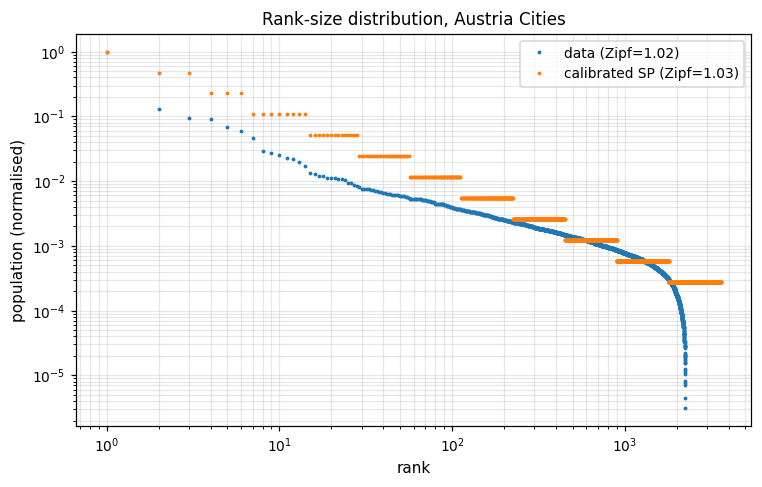

In [15]:
ex = next((c for c in CACHE.values() if "pop_data_sorted" in c), None)
if ex is not None:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    pd_ = ex["pop_data_sorted"]; ps_ = ex["sp_pop_sorted"]
    ax.loglog(np.arange(1, len(pd_) + 1), pd_ / pd_.max(), ".", ms=3,
              label=f"data (Zipf={float(ex['zipf_data']):.2f})")
    ax.loglog(np.arange(1, len(ps_) + 1), ps_ / ps_.max(), ".", ms=3,
              label=f"calibrated SP (Zipf={float(ex['zipf_sp']):.2f})")
    ax.set_xlabel("rank"); ax.set_ylabel("population (normalised)")
    ax.set_title(f"Rank-size distribution, {ex['name']}")
    ax.legend(); ax.grid(alpha=0.3, which="both")
    plt.tight_layout(); plt.show()

## Results

- Table 2, one realisation: mean rank SP 1.78, Hawkes 2.67, LGCP 2.78, Cox-Hawkes 3.22,
  Poisson 4.56. The SP is first on 5 of the 9 datasets.
- Mean JSD over 10 realisations, averaged over datasets: Cox-Hawkes 0.0016, SP 0.0019,
  LGCP 0.0026, Poisson 0.0038, Hawkes 0.0133. The SP has the largest spread after
  Hawkes (σ = 0.0029), so it is not the most reproducible model. Ranks on these means
  are in notebook 10.
- NN distances: mean rank Cox-Hawkes 2.11, SP 2.33, LGCP 2.67, Poisson 3.89, Hawkes 4.00.
  The SP is first on 5 datasets (RTE, ENEDIS, municipalities, German and Swiss stops).
  Poisson wins on the Austrian cities, Hawkes on the Belgian ones, Cox-Hawkes on the
  railway stations and LGCP on the roads. The NN JSD of the SP decreases with N
  (Spearman −0.65 with log N).
- Against N, the SP is first on 14 of the 28 (dataset, N) points.
- Cost exponents: SP 0.16, Hawkes 0.59, Cox-Hawkes 0.68. The LGCP exponent is negative
  (−0.34), since its time is set by the fixed number of SVI steps in this range of N.
- Population marks: the Zipf exponent is matched (slope capped at 2 on four datasets),
  but Δγ of the marked SP is anti-correlated with the data across datasets (−0.38, and
  −0.50 for the marked Hawkes). The level-based marks do not reproduce the coupling.